# **BCC Data Science Mini Bootcamp 2024 Tugas - Day II**

<img src="https://fiverr-res.cloudinary.com/images/t_main1,q_auto,f_auto,q_auto,f_auto/attachments/delivery/asset/d1c101ab4bdec5f4a2a9424c48346929-1687425922/scene1/draw-custom-offline-starting-soon-animated-pixel-art-twitch-screen.gif" alt="Pandas Logo" width="1000">

In [201]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [202]:
iris = load_wine()
df = pd.DataFrame(data= np.c_[iris['data'], iris['target']],
                     columns= iris['feature_names'] + ['target'])
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


## EDA

Ukuran Pusat Data

In [203]:
print("\nMean alcohol:", df['alcohol'].mean())
print("Median magnesium:", df['magnesium'].median())
print("Mode ash:", df['ash'].mode()[0])


Mean alcohol: 13.00061797752809
Median magnesium: 98.0
Mode ash: 2.28


Interquartile Range (IQR)

In [204]:
rentang = df['proline'].max() - df['proline'].min()
print("\nRentang proline: ", rentang)
print("Quantiles proline:")
df['proline'].quantile([0.25, 0.5, 0.75])


Rentang proline:  1402.0
Quantiles proline:


,proline
0.25,500.5
0.50,673.5
0.75,985.0


Jumlah Nilai Unik

In [205]:
print("\nJumlah nilai unik per kolom:")
df.nunique()


Jumlah nilai unik per kolom:


,0
alcohol,126
malic_acid,133
ash,79
alcalinity_of_ash,63
magnesium,53
total_phenols,97
flavanoids,132
nonflavanoid_phenols,39
proanthocyanins,101
color_intensity,132


loc (Label-based Indexing)

In [206]:
print("\nData pada baris pertama:")
df.loc[0]


Data pada baris pertama:


,0
alcohol,14.23
malic_acid,1.71
ash,2.43
alcalinity_of_ash,15.60
magnesium,127.00
total_phenols,2.80
flavanoids,3.06
nonflavanoid_phenols,0.28
proanthocyanins,2.29
color_intensity,5.64


iloc (Integer-based Indexing)

In [231]:
print("\nData 6 baris pertama, kolom 1-5:")
df.iloc[:6,0:5]


Data 6 baris pertama, kolom 1-5:


,alcohol,magnesium,flavonoids
0,150,74,57
1,153,74,45
2,153,62,33
3,189,51,28
4,159,88,29
5,169,89,40


Query with Logical Expression

In [208]:
df[(df['proline'] < 500) & (df['alcalinity_of_ash'] > 20)]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
71,13.86,1.51,2.67,25.0,86.0,2.95,2.86,0.21,1.87,3.38,1.36,3.16,410.0,1.0
72,13.49,1.66,2.24,24.0,87.0,1.88,1.84,0.27,1.03,3.74,0.98,2.78,472.0,1.0
79,12.70,3.87,2.40,23.0,101.0,2.83,2.55,0.43,1.95,2.57,1.19,3.13,463.0,1.0
86,12.16,1.61,2.31,22.8,90.0,1.78,1.69,0.43,1.56,2.45,1.33,2.26,495.0,1.0
91,12.00,1.51,2.42,22.0,86.0,1.45,1.25,0.50,1.63,3.60,1.05,2.65,450.0,1.0
92,12.69,1.53,2.26,20.7,80.0,1.38,1.46,0.58,1.62,3.05,0.96,2.06,495.0,1.0
102,12.34,2.45,2.46,21.0,98.0,2.56,2.11,0.34,1.31,2.80,0.80,3.38,438.0,1.0
105,12.42,2.55,2.27,22.0,90.0,1.68,1.84,0.66,1.42,2.70,0.86,3.30,315.0,1.0
107,12.72,1.75,2.28,22.5,84.0,1.38,1.76,0.48,1.63,3.30,0.88,2.42,488.0,1.0
111,12.52,2.43,2.17,21.0,88.0,2.55,2.27,0.26,1.22,2.00,0.90,2.78,325.0,1.0


Bar Plot

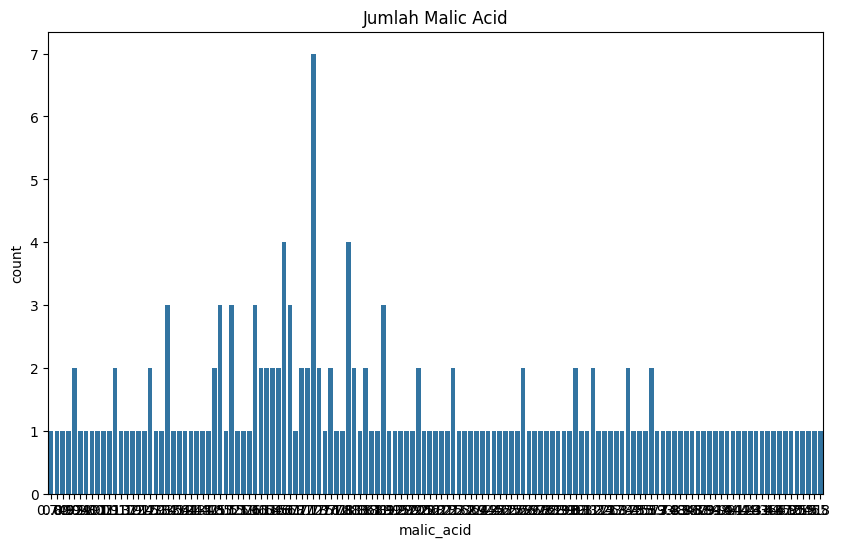

In [209]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='malic_acid')
plt.title('Jumlah Malic Acid')
plt.show()

Density Plot (KDE)

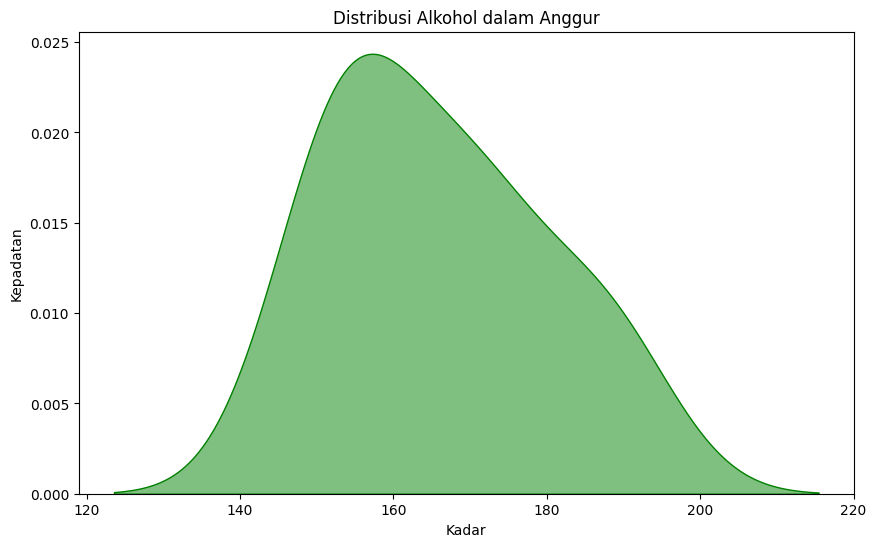

In [232]:
plt.figure(figsize=(10, 6))
sns.kdeplot(df['alcohol'], fill=True, color='green', alpha=0.5)
plt.title('Distribusi Alkohol dalam Anggur')
plt.xlabel('Kadar')
plt.ylabel('Kepadatan')
plt.show()

Heatmap

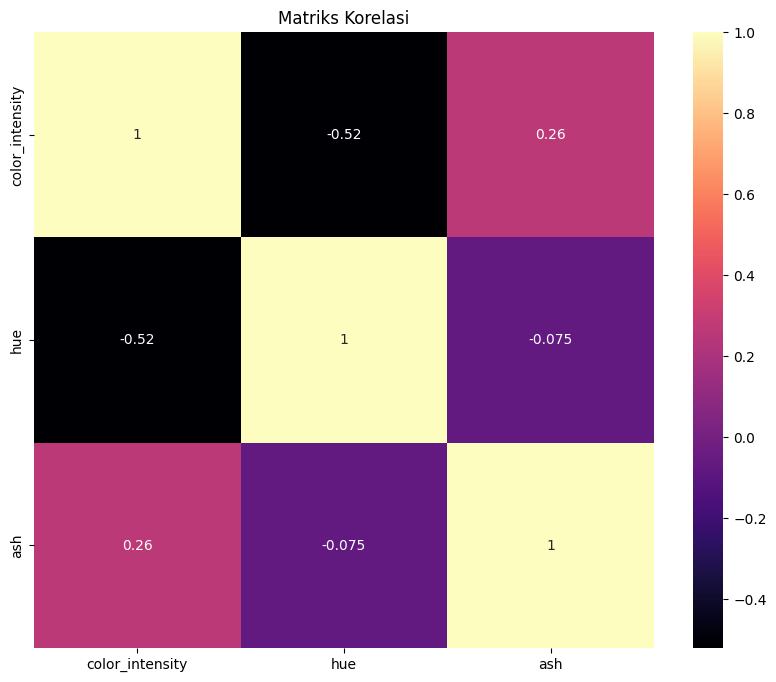

In [211]:
corr_matrix = df[['color_intensity', 'hue', 'ash']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='magma')
plt.title('Matriks Korelasi')
plt.show()

## Data Preprocessing

Missing Values

In [212]:
print("\nJumlah missing values:")
print(df.isnull().sum())


Jumlah missing values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


Drop Missing Values

In [213]:
df_cleaned = df.dropna()
print("\nUkuran data setelah drop NA:", df_cleaned.shape)


Ukuran data setelah drop NA: (178, 14)


Imputasi

In [214]:
baris_harga_isnull = df[df['alcohol'].isnull()]
baris_harga_isnull

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target


In [215]:
from sklearn.impute import SimpleImputer

In [216]:
imputer = SimpleImputer(strategy='mean')
df['alcohol'] = imputer.fit_transform(df[['alcohol']])

In [217]:
indexes = baris_harga_isnull.index
df.iloc[indexes]

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target


Duplication Handling

In [218]:
print("\nJumlah duplikasi:", df.duplicated().sum())
df_no_duplicates = df.drop_duplicates()
print("Ukuran data setelah menghapus duplikasi:", df_no_duplicates.shape)


Jumlah duplikasi: 0
Ukuran data setelah menghapus duplikasi: (178, 14)


Outliers Detection

In [219]:
Q1 = df['proline'].quantile(0.25)
Q3 = df['proline'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_no_duplicates[(df_no_duplicates['proline'] < (Q1 - 1.5 * IQR)) |
                            (df_no_duplicates['proline'] > (Q3 + 1.5 * IQR))]

# Menampilkan data yang dianggap outliers
print("Outliers yang terdeteksi:")
outliers

Outliers yang terdeteksi:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target


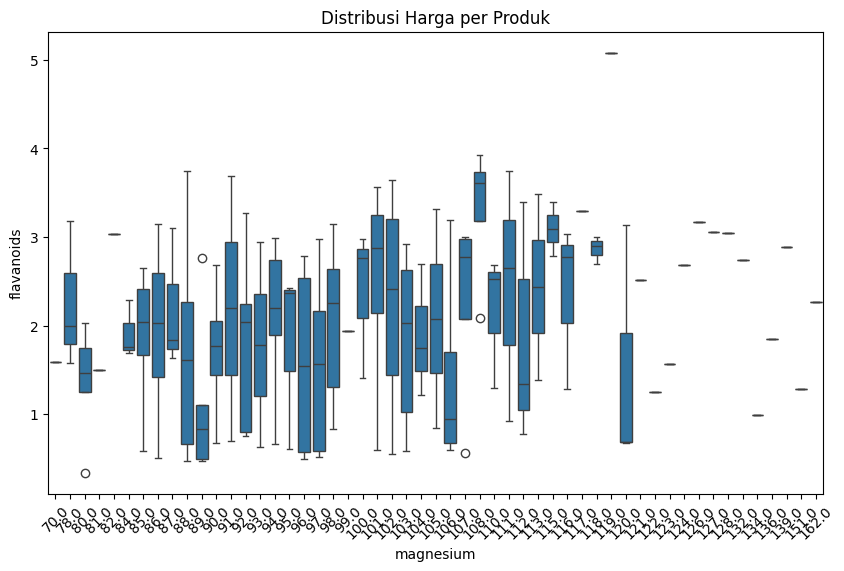

In [220]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_no_duplicates, x='magnesium', y='flavanoids')
plt.title('Distribusi Harga per Produk')
plt.xticks(rotation=45)
plt.show()

Outliers Handling

In [221]:
df_no_outliers = df_no_duplicates[(df_no_duplicates['magnesium'] >= lower_bound) & (df['magnesium'] <= upper_bound)]
print("\nUkuran data setelah menghapus outliers:", df_no_outliers.shape)


Ukuran data setelah menghapus outliers: (178, 14)


In [222]:
df_no_outliers['magnesium'] = np.where(df_no_duplicates['magnesium'] > upper_bound, upper_bound,  df_no_duplicates['magnesium'])

In [223]:
df_no_outliers.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


Mean Imputation

In [224]:
df['alcohol'] = df['alcohol'].fillna(df['alcohol'].mean())
df['ash'] = df['ash'].fillna(df['ash'].mean())

print("Setelah Mean Imputation untuk Alcohol dan Ash:")
print(df)
print("\n")

Setelah Mean Imputation untuk Alcohol dan Ash:
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

    

One-Hot Encoding

In [225]:
df_onehot = pd.get_dummies(df, columns=['proline', 'magnesium'], dtype=int)

print("Setelah One-Hot Encoding:")
print(df_onehot)
print("\n")

Setelah One-Hot Encoding:
     alcohol  malic_acid   ash  alcalinity_of_ash  total_phenols  flavanoids  \
0      14.23        1.71  2.43               15.6           2.80        3.06   
1      13.20        1.78  2.14               11.2           2.65        2.76   
2      13.16        2.36  2.67               18.6           2.80        3.24   
3      14.37        1.95  2.50               16.8           3.85        3.49   
4      13.24        2.59  2.87               21.0           2.80        2.69   
..       ...         ...   ...                ...            ...         ...   
173    13.71        5.65  2.45               20.5           1.68        0.61   
174    13.40        3.91  2.48               23.0           1.80        0.75   
175    13.27        4.28  2.26               20.0           1.59        0.69   
176    13.17        2.59  2.37               20.0           1.65        0.68   
177    14.13        4.10  2.74               24.5           2.05        0.76   

     nonflava

Label Encoding

In [226]:
le = LabelEncoder()
df['alcohol_Encoded'] = le.fit_transform(df['alcohol'])
df['magnesium_Encoded'] = le.fit_transform(df['magnesium'])

print("Setelah Label Encoding:")
print(df)
print("\n")

Setelah Label Encoding:
     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

     flavanoids  nonflavano

Scaling

In [227]:
np.random.seed(0)
data = {
    'alcohol': np.random.randint(150, 190, 10),
    'magnesium': np.random.randint(50, 100, 10),
    'flavonoids': np.random.randint(20, 60, 10)
}

df = pd.DataFrame(data)

print("Dataset awal:")
print(df)
print("\n")

Dataset awal:
   alcohol  magnesium  flavonoids
0      150         74          57
1      153         74          45
2      153         62          33
3      189         51          28
4      159         88          29
5      169         89          40
6      171         73          36
7      186         96          25
8      173         74          35
9      156         67          20




Min-Max Scaling

In [228]:
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_minmax.fit_transform(df),
                         columns=[col + '_minmax' for col in df.columns])

print("Setelah Min-Max Scaling:")
print(df_minmax)
print("\n")

Setelah Min-Max Scaling:
   alcohol_minmax  magnesium_minmax  flavonoids_minmax
0        0.000000          0.511111           1.000000
1        0.076923          0.511111           0.675676
2        0.076923          0.244444           0.351351
3        1.000000          0.000000           0.216216
4        0.230769          0.822222           0.243243
5        0.487179          0.844444           0.540541
6        0.538462          0.488889           0.432432
7        0.923077          1.000000           0.135135
8        0.589744          0.511111           0.405405
9        0.153846          0.355556           0.000000




## Data Modelling

K-Nearest Neighbors (KNN) Classification

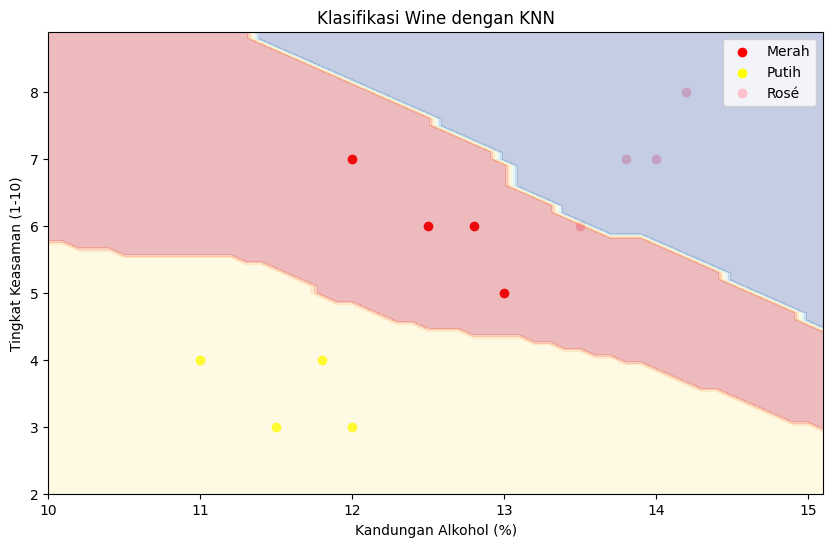

In [229]:
X = np.array([
    [12.5, 6], [13.0, 5], [12.0, 7], [12.8, 6],
    [11.5, 3], [11.0, 4], [12.0, 3], [11.8, 4],
    [14.0, 7], [13.5, 6], [14.2, 8], [13.8, 7]
])

y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2])

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)

plt.figure(figsize=(10, 6))
plt.scatter(X[y==0, 0], X[y==0, 1], color='red', label='Merah')
plt.scatter(X[y==1, 0], X[y==1, 1], color='yellow', label='Putih')
plt.scatter(X[y==2, 0], X[y==2, 1], color='pink', label='Rosé')
plt.xlabel('Kandungan Alkohol (%)')
plt.ylabel('Tingkat Keasaman (1-10)')
plt.legend()
plt.title('Klasifikasi Wine dengan KNN')

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)
plt.show()


# Evaluation

Accuracy

In [230]:
X = np.array([
    [12.5, 6], [13.0, 5], [12.0, 7], [12.8, 6],
    [11.5, 3], [11.0, 4], [12.0, 3], [11.8, 4],
    [14.0, 7], [13.5, 6], [14.2, 8], [13.8, 7]
])

y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')


Accuracy: 0.67
